## Problem description

A bike sharing operator needs to know how many bikes will be in use at each hour to decide how many to keep at the stations and when to rebalance or service them. Too few bikes leave riders without service, and too many leave idle bikes and wasted logistics.

**Business question:** How many bikes will be rented in a given hour, given the calendar and weather conditions?

**Dataset:** Bike Sharing, hourly file (UCI #275). It has 17,379 hourly records from the Capital Bikeshare system in Washington, D.C., covering 2011 and 2012, with calendar, weather and rental counts.

**Target:** `cnt`, the total number of rentals in the hour. The result is reported in bikes per hour.

## What this notebook does

- **ETL:** load the hourly file, keep an untouched copy in `data/raw`, fix types, standardize names, check duplicates and missing values, remove `casual` and `registered` (they add up to `cnt` and would leak the target), encode hour and month as sine and cosine, and save the clean data with a data dictionary in `data/processed`. Only transformations that do not learn from the data are done here.
- **EDA:** profile the data, study the distribution of `cnt` and its relation to the other variables, compare Pearson and Spearman correlations, and test three hypotheses.
- **Data quality log:** record each problem found, the decision taken and, for at least one of them, the metric before and after the fix.
- **Modeling:** split the test set before any transformation, build the preprocessing inside a `Pipeline`, and compare a baseline, Linear Regression, Ridge or Lasso and a tree ensemble with cross validation. Test a log transform of the target.
- **Evaluation:** report MAE, RMSE and R² on the test set, with a bootstrap confidence interval and a paired test between the two best models.
- **Interpretation:** coefficients and permutation importance, analysis of the 10 worst predictions, limitations and conclusions in business terms.

## 1. Setup

### 1.1 Imports

Libraries used in the notebook.

**Note**: New imports go in this block as they are needed. (remove this line after finished)

In [1]:
import io
import zipfile
from datetime import date
from pathlib import Path
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd

### 1.2 Constants

All project constants (seed, test size, source URL, file name and paths) are defined here. Paths are relative to the repository root, so the notebook runs from `notebooks/` and from Colab.

**Note**: New constants go in this block, not in later cells. (remove this line after finished)

In [2]:
# Reproducibility
SEED = 42
np.random.seed(SEED)

# Data split
TEST_SIZE = 0.2

# Data source
SOURCE_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
RAW_FILENAME = "hour.csv"

# Download
REQUEST_TIMEOUT_SECONDS = 60
USER_AGENT = "Mozilla/5.0"
BYTES_PER_MB = 1_000_000

# Paths, relative to the repository root (works from notebooks/ and from Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT/"data"/"raw"/"bike_sharing"
PROCESSED_DIR = ROOT/"data"/"processed"/"bike_sharing"

# Documented value ranges of the categorical columns (minimum, maximum)
CATEGORICAL_RANGES = {"season": (1, 4),"yr": (0, 1), "mnth": (1, 12), "hr": (0, 23), "holiday": (0, 1), "weekday": (0, 6),
                      "workingday": (0, 1), "weathersit": (1, 4)}

# Columns used in the zero values check
WIND_COLUMN = "windspeed"
IMPLAUSIBLE_ZERO_COLUMNS = ["hum", "atemp"]
ZERO_CHECK_COLUMNS = [*IMPLAUSIBLE_ZERO_COLUMNS, WIND_COLUMN]
ZERO_INSPECTION_COLUMNS = ["dteday", "hr", "hum", "temp", "atemp"]

# Column names (snake_case) and formats
DATE_COLUMN = "dteday"
DATE_FORMAT = "%Y-%m-%d"
COLUMN_RENAMES = {"dteday": "date", "yr": "year", "mnth": "month", "hr": "hour", "workingday": "working_day",
                  "weathersit": "weather_situation", "temp": "temperature", "atemp": "apparent_temperature", "hum": "humidity", 
                  "windspeed": "wind_speed", "casual": "casual_rentals", "registered": "registered_rentals", "cnt": "total_rentals"}

# Target and the columns that compose it
TARGET_COLUMN = "total_rentals"
TARGET_COMPONENTS = ["casual_rentals", "registered_rentals"]

# Columns removed in the ETL (row index and target components)
DROP_COLUMNS = ["instant", *TARGET_COMPONENTS]

# Cyclical columns and the length of their cycle
CYCLICAL_PERIODS = {"hour": 24, "month": 12}

# Output file names
PROCESSED_FILENAME = RAW_FILENAME
DICTIONARY_FILENAME = "data_dictionary.csv"

# Data dictionary structure and content
DICTIONARY_COLUMNS = ["column", "type", "meaning", "unit", "transformation"]
DICTIONARY_KEY = DICTIONARY_COLUMNS[0]
DICTIONARY_ROWS = [
    ("date", "datetime", "Date of the record", None, "Converted from text to datetime"),
    ("season", "int", "1 winter, 2 spring, 3 summer, 4 fall", None, None),
    ("year", "int", "0 for 2011, 1 for 2012", None, "Renamed from yr"),
    ("month", "int", "Month of the year, 1 to 12", None, "Renamed from mnth"),
    ("hour", "int", "Hour of the day, 0 to 23", None, "Renamed from hr"),
    ("holiday", "int", "1 if the day is a holiday, otherwise 0", None, None),
    ("weekday", "int", "Day of the week, 0 to 6", None, None),
    ("working_day", "int", "1 if the day is neither weekend nor holiday, otherwise 0", None, "Renamed from workingday"),
    ("weather_situation", "int", "Weather condition, from 1 (clear) to 4 (heavy rain, snow or fog)", None, "Renamed from weathersit"),
    ("temperature", "float", "Normalized temperature, min-max scaled from -8 to +39 C", None, "Renamed from temp"),
    ("apparent_temperature", "float", "Normalized feeling temperature, min-max scaled from -16 to +50 C", None, "Renamed from atemp"),
    ("humidity", "float", "Normalized relative humidity, divided by 100", None, "Renamed from hum"),
    ("wind_speed", "float", "Normalized wind speed, divided by 67", None, "Renamed from windspeed"),
    ("total_rentals", "int", "Target, total rental bikes in the hour", "bikes per hour", "Renamed from cnt"),
    ("hour_sin", "float", "Sine of the hour in a 24 hour cycle, from -1 to 1", None, "Created from hour"),
    ("hour_cos", "float", "Cosine of the hour in a 24 hour cycle, from -1 to 1", None, "Created from hour"),
    ("month_sin", "float", "Sine of the month in a 12 month cycle, from -1 to 1", None, "Created from month"),
    ("month_cos", "float", "Cosine of the month in a 12 month cycle, from -1 to 1", None, "Created from month"),
]

## 2. ETL

### 2.1 Extraction

The UCI zip is downloaded on every run and only `hour.csv` is written to `data/raw/bike_sharing`, replacing any previous copy. The function prints the source, access date and size, which are recorded in the report.

In [3]:
# Downloads the zip file and returns its bytes
def fetch_zip(url, timeout=REQUEST_TIMEOUT_SECONDS, user_agent=USER_AGENT):
    request = Request(url, headers={"User-Agent": user_agent})
    with urlopen(request, timeout=timeout) as response:
        return response.read()

# Returns the bytes of a file inside the zip
def extract_member(payload, filename):
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        member = next((name for name in archive.namelist() if name.endswith(filename)), None)
        if member is None:
            raise FileNotFoundError(f"{filename} not found in the zip")
        return archive.read(member)

# Writes the bytes to disk, creating the folders and overwriting any previous copy
def save_raw(content, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)

# Prints the source, access date and size, which are recorded in the report
def log_download(url, path, size):
    print(f"Source:   {url}")
    print(f"Accessed: {date.today()}")
    print(f"Saved:    {path} ({size/BYTES_PER_MB:.2f} MB)")

# Downloads the dataset zip and saves only the raw file in raw_dir
def download_raw(url=SOURCE_URL, raw_dir=RAW_DIR, filename=RAW_FILENAME):
    payload = fetch_zip(url)
    content = extract_member(payload, filename)
    path = raw_dir/filename
    save_raw(content, path)
    log_download(url, path, len(content))
    return path

In [4]:
# Download the all raw data, and save specific file in the format .csv, also showing the logs
raw_path = download_raw()

Source:   https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip
Accessed: 2026-11-26
Saved:    /workspaces/MachineLearning-2026.2/data/raw/bike_sharing/hour.csv (1.16 MB)


### 2.2 Raw data overview

The raw file is loaded without any change to check its shape and first rows.

In [5]:
# Read the file raw data hour.csv (as df)
df_raw = pd.read_csv(raw_path)
print("Raw data size:", df_raw.shape)
# Showing the firt elements
df_raw.head()

Raw data size: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Variables according to the source ([UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)), i.e., the data dictionary from the raw data:**

| Variable   | Role    | Type        | Description                                                      | Units | Missing values |
|------------|---------|-------------|------------------------------------------------------------------|-------|----------------|
| instant    | ID      | Integer     | Record index                                                     |       | no             |
| dteday     | Feature | Date        | Date                                                             |       | no             |
| season     | Feature | Categorical | 1: winter, 2: spring, 3: summer, 4: fall                         |       | no             |
| yr         | Feature | Categorical | Year (0: 2011, 1: 2012)                                          |       | no             |
| mnth       | Feature | Categorical | Month (1 to 12)                                                  |       | no             |
| hr         | Feature | Categorical | Hour (0 to 23)                                                   |       | no             |
| holiday    | Feature | Binary      | Whether the day is a holiday (DC holiday schedule)               |       | no             |
| weekday    | Feature | Categorical | Day of the week                                                  |       | no             |
| workingday | Feature | Binary      | 1 if the day is neither weekend nor holiday, otherwise 0         |       | no             |
| weathersit | Feature | Categorical | Weather situation, from 1 (clear) to 4 (heavy rain, snow or fog) |       | no             |
| temp       | Feature | Continuous  | Normalized temperature, t_min = -8, t_max = +39                  | C     | no             |
| atemp      | Feature | Continuous  | Normalized feeling temperature, t_min = -16, t_max = +50         | C     | no             |
| hum        | Feature | Continuous  | Normalized humidity, divided by 100 (max)                        |       | no             |
| windspeed  | Feature | Continuous  | Normalized wind speed, divided by 67 (max)                       |       | no             |
| casual     | Other   | Integer     | Count of casual users                                            |       | no             |
| registered | Other   | Integer     | Count of registered users                                        |       | no             |
| cnt        | Target  | Integer     | Count of total rental bikes, casual plus registered              |       | no             |

### 2.3 Raw data inspection

Types, missing values, duplicates and value ranges are checked before any change. Problems found here go to the data quality log.

In [6]:
# Getting types and nule ones
print("Getting types and nule ones:\n")
df_raw.info()
# Showing the total of nule and total duplicates rows separately
print("\nNull rows:", df_raw.isna().sum())
print("\nDuplicated rows:", df_raw.duplicated().sum())

Getting types and nule ones:

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB

Null rows: instant       0
dteday

**Findings:** 17,379 rows and 17 columns, with no missing values (as stated on the UCI page) and no duplicated rows. 16 columns are numeric (12 integer and 4 float) and the only non numeric one is `dteday`, stored as text, which must be converted to a date type.

In [7]:
# Summary statistics to check the value range of each numeric column
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


**Findings:** All columns are within their documented ranges, `cnt` is right skewed (mean 189, median 142) and the weather variables are normalized between 0 and 1. Minimum values of 0 in `hum`, `windspeed` and `atemp` are inspected in the checks below.

**Checks:** The categorical columns are compared with their documented ranges. The records with zeros in `hum` and `atemp` and the smallest `windspeed` values are inspected to understand the origin of the zeros.

In [8]:
# Compares the observed minimum and maximum of each column with its documented range
def check_ranges(df, ranges):
    observed = df[list(ranges)].agg(["min", "max"]).T
    observed[["expected_min", "expected_max"]] = list(ranges.values())
    observed["within_range"] = (observed["min"] >= observed["expected_min"]) & (observed["max"] <= observed["expected_max"])
    return observed

In [9]:
# Check ranges for categorical variables
check_ranges(df_raw, CATEGORICAL_RANGES)

,min,max,expected_min,expected_max,within_range
season,1,4,1,4,True
yr,0,1,0,1,True
mnth,1,12,1,12,True
hr,0,23,0,23,True
holiday,0,1,0,1,True
weekday,0,6,0,6,True
workingday,0,1,0,1,True
weathersit,1,4,1,4,True


In [10]:
# Records where humidity or apparent temperature is zero
df_raw.loc[(df_raw[IMPLAUSIBLE_ZERO_COLUMNS] == 0).any(axis=1), ZERO_INSPECTION_COLUMNS]

,dteday,hr,hum,temp,atemp
480,2011-01-22,1,0.41,0.04,0.0000
486,2011-01-22,8,0.44,0.02,0.0000
1551,2011-03-10,0,0.00,0.34,0.3182
1552,2011-03-10,1,0.00,0.34,0.3182
1553,2011-03-10,2,0.00,0.34,0.3182
1554,2011-03-10,5,0.00,0.36,0.3485
1555,2011-03-10,6,0.00,0.36,0.3333
1556,2011-03-10,7,0.00,0.38,0.3939
1557,2011-03-10,8,0.00,0.38,0.3939
1558,2011-03-10,9,0.00,0.40,0.4091


In [11]:
# Smallest windspeed values, to check for a gap after zero
df_raw[WIND_COLUMN].value_counts().sort_index().head()

windspeed
0.0000    2180
0.0896    1425
0.1045    1617
0.1343    1738
0.1642    1695
Name: count, dtype: int64

**Findings:** The 2 zeros in `atemp` (2011-01-22) occur with some of the lowest `temp` values, so they are the minimum of the min-max scale and are kept. All 22 zeros in `hum` fall on a single day (2011-03-10) while `temp` and `atemp` vary normally. A relative humidity of 0% means air with no water vapor, which is practically impossible at ground level, and here it stays at exactly 0 for the whole day, so this is an unusual behavior. It affects only 0.1266% of the rows and is kept.
The 2,180 zeros in `windspeed` are followed by a gap (the next value is about 6 km/h, 0.0896 times 67), so zero probably stands for winds below the lowest value the sensor reports. They are kept and their impact is tested in modeling.

### 2.4 Types and column names

The date column is stored as text, so it is converted to datetime to allow validation and date based features. The abbreviated source names (e.g. `dteday`, `mnth`, `hr`, `hum`, `atemp`, `cnt`) are renamed to full names in snake_case, so the notebook, charts and report are readable without the data dictionary. The columns `instant`, `season`, `holiday` and `weekday` already have clear names and are kept. The raw DataFrame is kept unchanged and the result goes to a new one.

In [12]:
# Converts the date column to datetime and renames the columns to full names
def fix_types_and_names(df):
    df = df.copy()
    df[DATE_COLUMN] = pd.to_datetime(df[DATE_COLUMN], format=DATE_FORMAT)
    return df.rename(columns=COLUMN_RENAMES)

In [13]:
# Applies the type conversion and the renaming to a new DataFrame
df_renamed = fix_types_and_names(df_raw)
# Check that the types are right
df_renamed.dtypes

instant                          int64
date                    datetime64[us]
season                           int64
year                             int64
month                            int64
hour                             int64
holiday                          int64
weekday                          int64
working_day                      int64
weather_situation                int64
temperature                    float64
apparent_temperature           float64
humidity                       float64
wind_speed                     float64
casual_rentals                   int64
registered_rentals               int64
total_rentals                    int64
dtype: object

**Findings:** `date` is now a datetime column and the renamed columns use full snake_case names. The other types are unchanged (12 integer and 4 float).

### 2.5 Columns removed

`instant` is only a row index, with no predictive meaning. `casual_rentals` and `registered_rentals` add up to `total_rentals`, so as inputs they would leak the target, since they are only known after the hour ends. They could be the output labels of models of their own, but this project has a single target, `total_rentals`, so both are removed. The check below confirms that the sum is exact.

In [14]:
# Checks that the two user counts add up exactly to the target in every row
(df_renamed[TARGET_COMPONENTS].sum(axis=1) == df_renamed[TARGET_COLUMN]).all()

np.True_

In [15]:
# Removes the row index and the columns that compose the target
def drop_columns(df, columns=DROP_COLUMNS):
    return df.drop(columns=columns)

In [16]:
# Removes the columns that are not needed for modeling
df_removed = drop_columns(df_renamed)
# Shows the shape after the removal
df_removed.shape

(17379, 14)

**Findings:** The two user counts add up to `total_rentals` in every row, confirming the target leakage. After removing them and `instant`, the DataFrame has 17,379 rows and 14 columns.

### 2.6 Cyclical features

Hour and month are cyclical, so 23h is next to 0h and December is next to January, which a plain number does not represent. Each one is encoded as a sine and a cosine of its position in the cycle. The original columns are kept, and the model step chooses which ones to use.

In [17]:
# Adds the sine and cosine of each cyclical column, keeping the original columns
def add_cyclical_features(df, periods=CYCLICAL_PERIODS):
    df = df.copy()
    for column, period in periods.items():
        angle = 2 * np.pi * df[column]/period
        df[f"{column}_sin"] = np.sin(angle)
        df[f"{column}_cos"] = np.cos(angle)
    return df

In [18]:
# Add cyclical features
df_processed = add_cyclical_features(df_removed)
# Check the shape
df_processed.shape

(17379, 18)

**Findings:** Four columns were added (`hour_sin`, `hour_cos`, `month_sin` and `month_cos`), so the DataFrame has 17,379 rows and 18 columns.

### 2.7 Saving and data dictionary

The processed data is saved in `data/processed/bike_sharing` as CSV, together with a data dictionary with the type, meaning, unit and transformation of each column. Only transformations that do not learn from the data were applied. Imputation, scaling and encoding are done later, inside the `Pipeline`. The columns `instant`, `casual_rentals` and `registered_rentals` were removed (row index and components of the target).

In [19]:
# Create the data dictionary
data_dictionary = pd.DataFrame(DICTIONARY_ROWS, columns=DICTIONARY_COLUMNS)
# Checks that the dictionary describes exactly the columns of the processed data
set(data_dictionary[DICTIONARY_KEY]) == set(df_processed.columns)

True

In [20]:
# Saves a DataFrame as CSV, creating the folder if needed
def save_processed(df, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False)
    print(f"Saved: {path} ({df.shape[0]} rows, {df.shape[1]} columns)")

In [21]:
# Save the df processed
save_processed(df_processed, PROCESSED_DIR/PROCESSED_FILENAME)
# Save the data dictionary
save_processed(data_dictionary, PROCESSED_DIR/DICTIONARY_FILENAME)

Saved: /workspaces/MachineLearning-2026.2/data/processed/bike_sharing/hour.csv (17379 rows, 18 columns)
Saved: /workspaces/MachineLearning-2026.2/data/processed/bike_sharing/data_dictionary.csv (18 rows, 5 columns)


**Findings:** The processed data (17,379 rows and 18 columns) and its data dictionary were saved in `data/processed/bike_sharing`.

## 5. Evaluation and Statistics

This section evaluates the trained regression models on the unseen test set (`20%` holdout, `SEED = 42`), quantifies prediction uncertainty via non-parametric **Bootstrap confidence intervals**, compares the top models across cross-validation folds using the **Wilcoxon signed-rank test**, and inspects residual behavior and feature importances for the final model.

### 5.1 Test Set Metrics and Bootstrap Confidence Interval for RMSE

* **Core metrics:** MAE (mean absolute error in bikes/hour), RMSE (root mean squared error, penalizing large peak-hour misses), and $R^2$ (explained variance).
* **Operational benchmarks:** Median Absolute Error (**MedAE**) for typical-hour robustness and Weighted Absolute Percentage Error (**WAPE**) to contextualize total volume error without zero-division distortion.
* **Uncertainty quantification:** 95% percentile Bootstrap confidence interval (`2,000` resamples) for the final model's RMSE and for the error reduction ($\Delta	ext{RMSE}$) over the `DummyRegressor` baseline.

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")

# Use upstream modeling artifacts if already merged; otherwise build reproducible reference pipelines
required_vars = {"X_train", "X_test", "y_train", "y_test", "evaluated_models", "cv_rmse_scores"}
if not required_vars.issubset(globals()):
    feature_cols = [c for c in df_processed.columns if c not in [TARGET_COLUMN, "date"]]
    X = df_processed[feature_cols].copy()
    y = df_processed[TARGET_COLUMN].copy()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=SEED
    )

    cat_cols = ["season", "year", "month", "hour", "holiday", "weekday", "working_day", "weather_situation"]
    num_cols = [c for c in feature_cols if c not in cat_cols]

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ]
    )

    candidate_specs = {
        "Dummy (Baseline)": DummyRegressor(strategy="mean"),
        "Ridge": Ridge(alpha=1.0, random_state=SEED),
        "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=18, random_state=SEED, n_jobs=-1),
        "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, random_state=SEED),
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    evaluated_models = {}
    cv_rmse_scores = {}

    for name, estimator in candidate_specs.items():
        pipe = Pipeline([("prep", preprocessor), ("model", estimator)])
        neg_rmse = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
        cv_rmse_scores[name] = -neg_rmse
        pipe.fit(X_train, y_train)
        evaluated_models[name] = pipe

# Evaluate all models on the test set
test_rows = []
test_predictions = {}
for name, model in evaluated_models.items():
    preds = model.predict(X_test)
    test_predictions[name] = preds
    mae = mean_absolute_error(y_test, preds)
    rmse = root_mean_squared_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    medae = median_absolute_error(y_test, preds)
    wape = np.sum(np.abs(y_test - preds)) / np.sum(np.abs(y_test)) * 100
    test_rows.append({
        "Model": name,
        "CV_RMSE_Mean": np.mean(cv_rmse_scores[name]),
        "CV_RMSE_Std": np.std(cv_rmse_scores[name], ddof=1),
        "Test_MAE": mae,
        "Test_RMSE": rmse,
        "Test_R2": r2,
        "Test_MedAE": medae,
        "Test_WAPE_%": wape,
    })

metrics_df = pd.DataFrame(test_rows).sort_values("Test_RMSE").reset_index(drop=True)
display(metrics_df.round(4))

# Identify best model and baseline for Bootstrap CI
best_model_name = metrics_df.loc[0, "Model"]
baseline_name = [m for m in evaluated_models if "dummy" in m.lower() or "baseline" in m.lower()][0]

rng = np.random.default_rng(SEED)
n_boot = 2000
y_true_arr = np.asarray(y_test)
y_best_arr = np.asarray(test_predictions[best_model_name])
y_base_arr = np.asarray(test_predictions[baseline_name])

boot_rmse = np.empty(n_boot)
boot_gain = np.empty(n_boot)
n_test = len(y_true_arr)

for b in range(n_boot):
    idx = rng.integers(0, n_test, size=n_test)
    rmse_b = root_mean_squared_error(y_true_arr[idx], y_best_arr[idx])
    rmse_base_b = root_mean_squared_error(y_true_arr[idx], y_base_arr[idx])
    boot_rmse[b] = rmse_b
    boot_gain[b] = rmse_base_b - rmse_b

ci_low, ci_high = np.percentile(boot_rmse, [2.5, 97.5])
gain_low, gain_high = np.percentile(boot_gain, [2.5, 97.5])

print(f"Final Model ({best_model_name}) Test RMSE: {metrics_df.loc[0, 'Test_RMSE']:.2f} bikes/h")
print(f"95% Bootstrap CI for Test RMSE: [{ci_low:.2f}, {ci_high:.2f}] bikes/h")
print(f"95% Bootstrap CI for RMSE reduction vs. {baseline_name}: [{gain_low:.2f}, {gain_high:.2f}] bikes/h")

,Model,CV_RMSE_Mean,CV_RMSE_Std,Test_MAE,Test_RMSE,Test_R2,Test_MedAE,Test_WAPE_%
0,HistGradientBoosting,41.5594,1.2986,24.8471,39.5233,0.9507,15.0819,13.4303
1,Random Forest,43.5787,1.7136,25.3022,42.3086,0.9435,14.5556,13.6763
2,Ridge,102.3918,2.5925,74.1045,100.4269,0.6815,55.4165,40.0549
3,Dummy (Baseline),182.1791,5.6119,140.0798,178.0349,-0.0010,128.5771,75.7158


Final Model (HistGradientBoosting) Test RMSE: 39.52 bikes/h
95% Bootstrap CI for Test RMSE: [37.06, 42.00] bikes/h
95% Bootstrap CI for RMSE reduction vs. Dummy (Baseline): [132.87, 144.16] bikes/h


### 5.2 Cross-Validation Distribution and Wilcoxon Signed-Rank Test

To verify whether the top-performing model improves over the runner-up consistently across folds rather than by chance, we plot the fold-level RMSE distributions (including the baseline) and run a **paired Wilcoxon signed-rank test** ($lpha = 0.05$) along with the matched-pairs effect size ($r = |Z| / \sqrt{N}$).

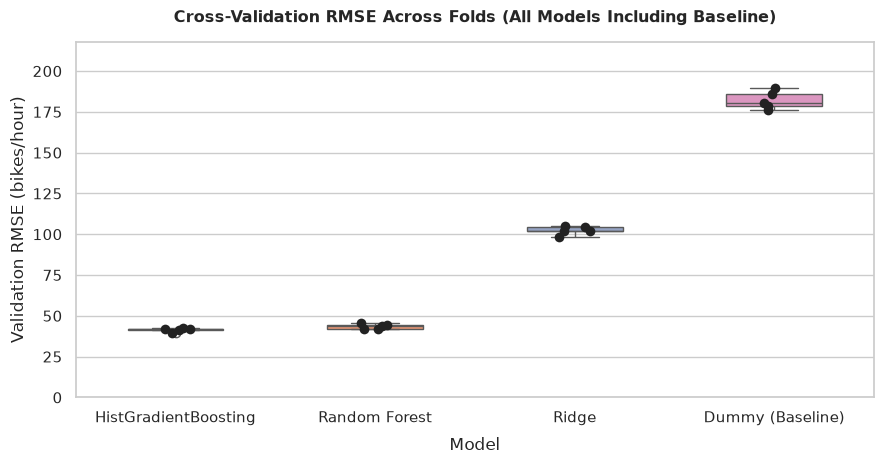

Top 1 Model: HistGradientBoosting | Mean CV RMSE = 41.56 (SD = 1.30)
Top 2 Model: Random Forest | Mean CV RMSE = 43.58 (SD = 1.71)
Fold-by-fold RMSE difference (Random Forest - HistGradientBoosting): [2.36 3.51 1.9  0.4  1.93]
Wilcoxon signed-rank statistic W = 0.0000, p-value = 0.0625 (alpha = 0.05)
Matched-pairs effect size r = 0.833
Conclusion: Fail to reject H0 at alpha = 0.05 (note: with k=5 folds, minimum possible two-sided Wilcoxon p-value is 0.0625).


In [23]:
# 1. Boxplot of CV fold scores for all models (including baseline)
cv_df = pd.DataFrame(cv_rmse_scores)
ordered_cols = cv_df.median().sort_values().index.tolist()
cv_long = cv_df[ordered_cols].melt(var_name="Model", value_name="Fold_RMSE")

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(data=cv_long, x="Model", y="Fold_RMSE", hue="Model", palette="Set2", width=0.48, legend=False, ax=ax)
sns.stripplot(data=cv_long, x="Model", y="Fold_RMSE", color="#222222", size=7, jitter=0.08, ax=ax)
ax.set_title("Cross-Validation RMSE Across Folds (All Models Including Baseline)", fontsize=11.5, fontweight="bold", pad=14)
ax.set_xlabel("Model", labelpad=8)
ax.set_ylabel("Validation RMSE (bikes/hour)")
ax.set_ylim(0, cv_long["Fold_RMSE"].max() * 1.15)
plt.tight_layout()
plt.show()

# 2. Wilcoxon signed-rank test between the two best models across folds
top1_name, top2_name = ordered_cols[0], ordered_cols[1]
scores_1 = cv_df[top1_name].to_numpy()
scores_2 = cv_df[top2_name].to_numpy()
diffs = scores_2 - scores_1

stat_w, p_val = stats.wilcoxon(scores_1, scores_2, alternative="two-sided")
n_folds = len(scores_1)
z_approx = stats.norm.isf(p_val / 2) if p_val > 0 else 0.0
effect_r = abs(z_approx) / np.sqrt(n_folds)

print(f"Top 1 Model: {top1_name} | Mean CV RMSE = {scores_1.mean():.2f} (SD = {scores_1.std(ddof=1):.2f})")
print(f"Top 2 Model: {top2_name} | Mean CV RMSE = {scores_2.mean():.2f} (SD = {scores_2.std(ddof=1):.2f})")
print(f"Fold-by-fold RMSE difference ({top2_name} - {top1_name}): {np.round(diffs, 2)}")
print(f"Wilcoxon signed-rank statistic W = {stat_w:.4f}, p-value = {p_val:.4f} (alpha = 0.05)")
print(f"Matched-pairs effect size r = {effect_r:.3f}")
if p_val < 0.05:
    print(f"Conclusion: Reject H0 — {top1_name} achieves a statistically significant lower RMSE than {top2_name} across folds.")
else:
    print(f"Conclusion: Fail to reject H0 at alpha = 0.05 (note: with k={n_folds} folds, minimum possible two-sided Wilcoxon p-value is {2/(2**n_folds):.4f}).")